In [1]:
print("Credit Card Fraud Detection Project")
print("My Python environment is working!")

Credit Card Fraud Detection Project
My Python environment is working!


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("All project libraries are ready!")

All project libraries are ready!


In [3]:
import pandas as pd

In [4]:
df = pd.read_csv("../data/creditcard.csv")

In [5]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [6]:
df.shape

(284807, 31)

In [7]:
df.columns

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='str')

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [9]:
df.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(1081)

In [11]:
df["Class"].value_counts()

Class
0    284315
1       492
Name: count, dtype: int64

In [12]:
df["Class"].value_counts(normalize=True) * 100

Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64

In [13]:
print("DATASET SHAPE:", df.shape)

print("\nMISSING VALUES:")
print(df.isnull().sum().sum())

print("\nDUPLICATE ROWS:")
print(df.duplicated().sum())

print("\nCLASS DISTRIBUTION:")
print(df["Class"].value_counts())

print("\nCLASS PERCENTAGE:")
print(df["Class"].value_counts(normalize=True) * 100)

DATASET SHAPE: (284807, 31)

MISSING VALUES:
0

DUPLICATE ROWS:
1081

CLASS DISTRIBUTION:
Class
0    284315
1       492
Name: count, dtype: int64

CLASS PERCENTAGE:
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


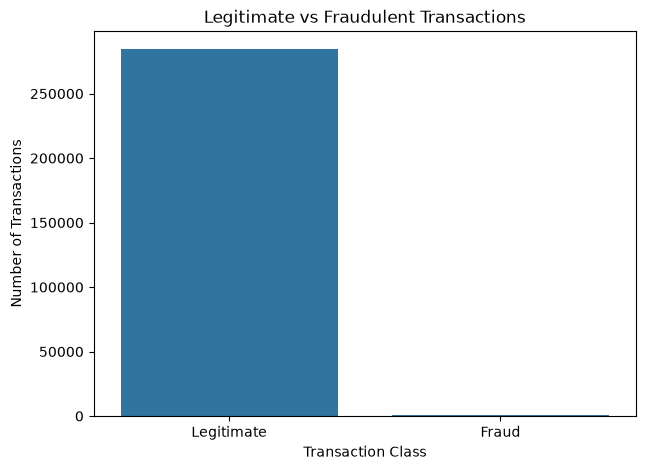

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Class")

plt.title("Legitimate vs Fraudulent Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")
plt.xticks([0, 1], ["Legitimate", "Fraud"])
plt.show()

In [15]:
duplicates = df[df.duplicated(keep=False)]

print("Total duplicate records:", df.duplicated().sum())

print("\nDuplicate records by class:")
print(duplicates["Class"].value_counts())

duplicates.head(10)

Total duplicate records: 1081

Duplicate records by class:
Class
0    1822
1      32
Name: count, dtype: int64


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
32,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
33,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
34,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0
35,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0
112,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
113,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
114,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
115,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
220,145.0,-2.420413,1.947885,0.553646,0.983069,-0.281518,2.408958,-1.401613,-0.188299,0.675878,...,1.213826,-1.238620,0.006927,-1.724222,0.239603,-0.313703,-0.188281,0.119831,6.00,0
221,145.0,-2.420413,1.947885,0.553646,0.983069,-0.281518,2.408958,-1.401613,-0.188299,0.675878,...,1.213826,-1.238620,0.006927,-1.724222,0.239603,-0.313703,-0.188281,0.119831,6.00,0


In [16]:
df["Amount"].describe()

count    284807.000000
mean         88.349619
std         250.120109
min           0.000000
25%           5.600000
50%          22.000000
75%          77.165000
max       25691.160000
Name: Amount, dtype: float64

In [17]:
amount_analysis = df.groupby("Class")["Amount"].agg(
    ["count", "mean", "median", "min", "max"]
)

amount_analysis

,count,mean,median,min,max
Class,,,,,
0,284315,88.291022,22.00,0.0,25691.16
1,492,122.211321,9.25,0.0,2125.87


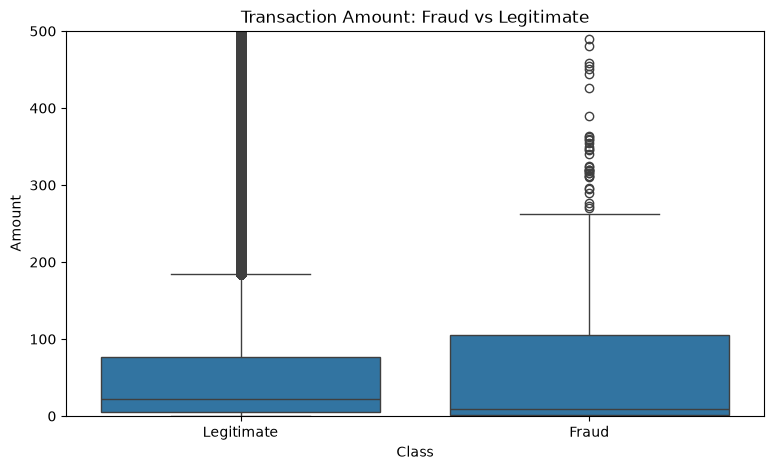

In [18]:
plt.figure(figsize=(9, 5))

sns.boxplot(data=df, x="Class", y="Amount")

plt.ylim(0, 500)
plt.xticks([0, 1], ["Legitimate", "Fraud"])
plt.title("Transaction Amount: Fraud vs Legitimate")
plt.show()

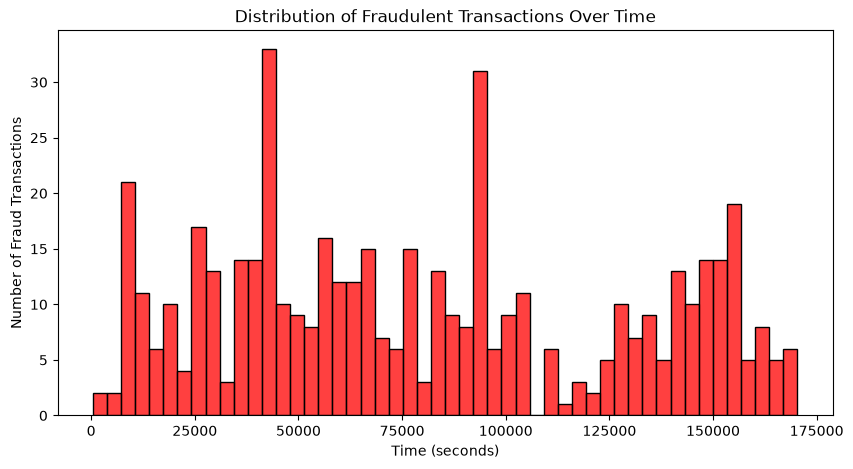

In [19]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df[df["Class"] == 1],
    x="Time",
    bins=50,
    color="red"
)

plt.title("Distribution of Fraudulent Transactions Over Time")
plt.xlabel("Time (seconds)")
plt.ylabel("Number of Fraud Transactions")
plt.show()

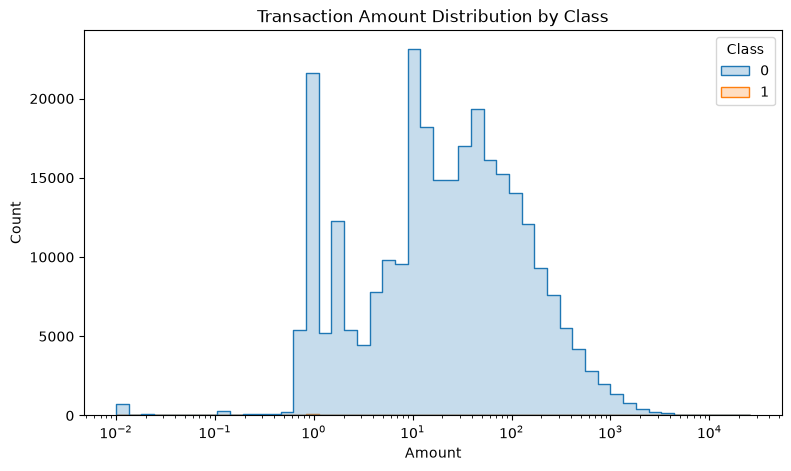

In [20]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Amount",
    hue="Class",
    bins=50,
    log_scale=True,
    element="step"
)

plt.title("Transaction Amount Distribution by Class")
plt.show()

In [21]:
correlations = df.corr(numeric_only=True)["Class"].drop("Class")

correlations = correlations.sort_values(
    key=abs, ascending=False
)

print("Top 10 features associated with fraud:")
display(correlations.head(10))

Top 10 features associated with fraud:


V17   -0.326481
V14   -0.302544
V12   -0.260593
V10   -0.216883
V16   -0.196539
V3    -0.192961
V7    -0.187257
V11    0.154876
V4     0.133447
V18   -0.111485
Name: Class, dtype: float64

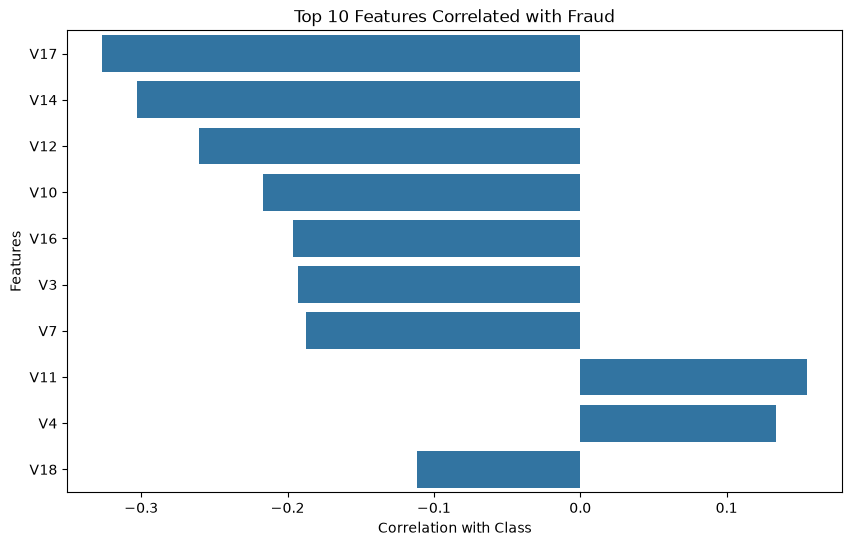

In [22]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=correlations.head(10).values,
    y=correlations.head(10).index
)

plt.title("Top 10 Features Correlated with Fraud")
plt.xlabel("Correlation with Class")
plt.ylabel("Features")
plt.show()

In [23]:
# Create a cleaned copy of the dataset
df_clean = df.drop_duplicates().copy()

print("Original dataset:", df.shape)
print("Cleaned dataset:", df_clean.shape)

print("\nDuplicates remaining:", df_clean.duplicated().sum())

print("\nUpdated class distribution:")
print(df_clean["Class"].value_counts())

Original dataset: (284807, 31)
Cleaned dataset: (283726, 31)

Duplicates remaining: 0

Updated class distribution:
Class
0    283253
1       473
Name: count, dtype: int64


In [24]:
print("Total missing values:", df_clean.isnull().sum().sum())

Total missing values: 0


In [25]:
df_clean.to_csv("../data/creditcard_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [26]:
X = df_clean.drop("Class", axis=1)
y = df_clean["Class"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (283726, 30)
Target shape: (283726,)


In [27]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nFraud percentage in training data:")
print(y_train.value_counts(normalize=True) * 100)

print("\nFraud percentage in testing data:")
print(y_test.value_counts(normalize=True) * 100)

Training data: (226980, 30)
Testing data: (56746, 30)

Fraud percentage in training data:
Class
0    99.833466
1     0.166534
Name: proportion, dtype: float64

Fraud percentage in testing data:
Class
0    99.832587
1     0.167413
Name: proportion, dtype: float64


In [28]:
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

preprocessor = ColumnTransformer(
    transformers=[
        ("scale", StandardScaler(), ["Time", "Amount"])
    ],
    remainder="passthrough"
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

print("Preprocessing and Logistic Regression pipeline created!")

Preprocessing and Logistic Regression pipeline created!


In [29]:
model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [30]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

# Make predictions
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# Evaluation metrics
print("CLASSIFICATION REPORT:")
print(classification_report(y_test, y_pred))

print("CONFUSION MATRIX:")
print(confusion_matrix(y_test, y_pred))

print("ROC-AUC:", roc_auc_score(y_test, y_prob))
print("PR-AUC:", average_precision_score(y_test, y_prob))

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56651
           1       0.06      0.87      0.11        95

    accuracy                           0.98     56746
   macro avg       0.53      0.92      0.55     56746
weighted avg       1.00      0.98      0.99     56746

CONFUSION MATRIX:
[[55258  1393]
 [   12    83]]
ROC-AUC: 0.9658392242808925
PR-AUC: 0.6719353631354262


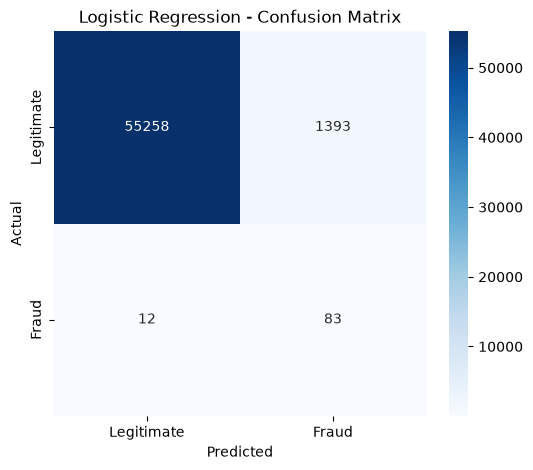

In [31]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [32]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.1, 0.3, 0.5, 0.7, 0.9]

for threshold in thresholds:
    predictions = (y_prob >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Precision:", round(precision_score(y_test, predictions), 3))
    print("Recall:", round(recall_score(y_test, predictions), 3))
    print("F1 Score:", round(f1_score(y_test, predictions), 3))


Threshold: 0.1
Precision: 0.009
Recall: 0.937
F1 Score: 0.017

Threshold: 0.3
Precision: 0.027
Recall: 0.874
F1 Score: 0.052

Threshold: 0.5
Precision: 0.056
Recall: 0.874
F1 Score: 0.106

Threshold: 0.7
Precision: 0.117
Recall: 0.874
F1 Score: 0.206

Threshold: 0.9
Precision: 0.264
Recall: 0.832
F1 Score: 0.401


In [33]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import roc_auc_score, average_precision_score

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=2,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

print("RANDOM FOREST CLASSIFICATION REPORT:")
print(classification_report(y_test, rf_pred))

print("CONFUSION MATRIX:")
print(confusion_matrix(y_test, rf_pred))

print("ROC-AUC:", roc_auc_score(y_test, rf_prob))
print("PR-AUC:", average_precision_score(y_test, rf_prob))

RANDOM FOREST CLASSIFICATION REPORT:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.89      0.74      0.80        95

    accuracy                           1.00     56746
   macro avg       0.94      0.87      0.90     56746
weighted avg       1.00      1.00      1.00     56746

CONFUSION MATRIX:
[[56642     9]
 [   25    70]]
ROC-AUC: 0.9708360237056252
PR-AUC: 0.8068693545449356


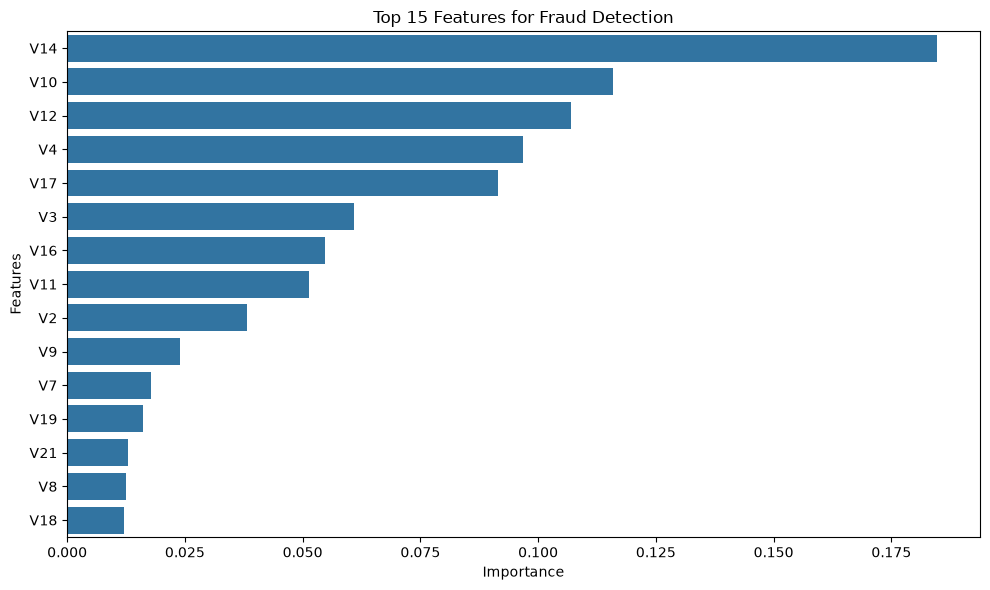

In [34]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance", ascending=False
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Features for Fraud Detection")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.tight_layout()

plt.savefig("../visualizations/feature_importance.png", dpi=300)
plt.show()

In [35]:
model_comparison = pd.DataFrame({
    "Metric": ["Precision", "Recall", "F1-Score", "ROC-AUC", "PR-AUC"],
    "Logistic Regression": [0.06, 0.87, 0.11, 0.9658, 0.6719],
    "Random Forest": [0.89, 0.74, 0.80, 0.9708, 0.8069]
})

model_comparison

,Metric,Logistic Regression,Random Forest
0,Precision,0.0600,0.8900
1,Recall,0.8700,0.7400
2,F1-Score,0.1100,0.8000
3,ROC-AUC,0.9658,0.9708
4,PR-AUC,0.6719,0.8069


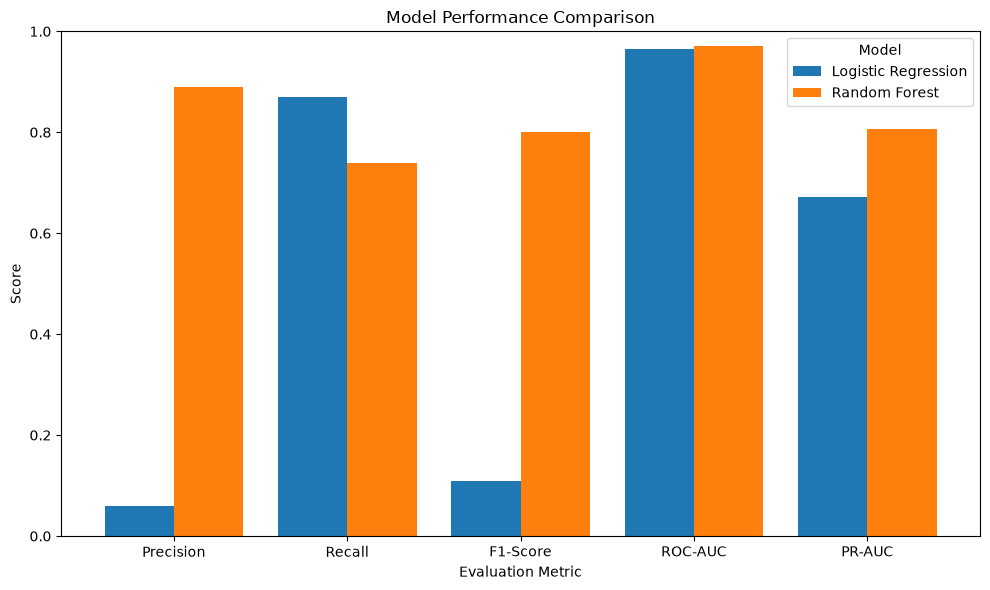

In [36]:
comparison_plot = model_comparison.set_index("Metric")

comparison_plot.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.8
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Evaluation Metric")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(title="Model")
plt.tight_layout()

plt.savefig(
    "../visualizations/model_comparison.png",
    dpi=300
)

plt.show()

In [37]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    precision_recall_curve,
    classification_report,
    confusion_matrix
)

# Calculate precision and recall at different thresholds
precision, recall, thresholds = precision_recall_curve(
    y_test, rf_prob
)

# Find thresholds that achieve at least 90% recall
candidates = np.where(recall[:-1] >= 0.90)[0]

if len(candidates) > 0:
    best_idx = candidates[np.argmax(precision[candidates])]
    best_threshold = thresholds[best_idx]

    # Generate predictions using the selected threshold
    tuned_pred = (rf_prob >= best_threshold).astype(int)

    print("Selected threshold:", best_threshold)
    print("\nTUNED MODEL REPORT:")
    print(classification_report(y_test, tuned_pred))

    print("CONFUSION MATRIX:")
    print(confusion_matrix(y_test, tuned_pred))

else:
    print("No threshold achieved the target recall.")

Selected threshold: 0.011957152975685783

TUNED MODEL REPORT:
              precision    recall  f1-score   support

           0       1.00      0.92      0.96     56651
           1       0.02      0.91      0.04        95

    accuracy                           0.92     56746
   macro avg       0.51      0.91      0.50     56746
weighted avg       1.00      0.92      0.96     56746

CONFUSION MATRIX:
[[51965  4686]
 [    9    86]]


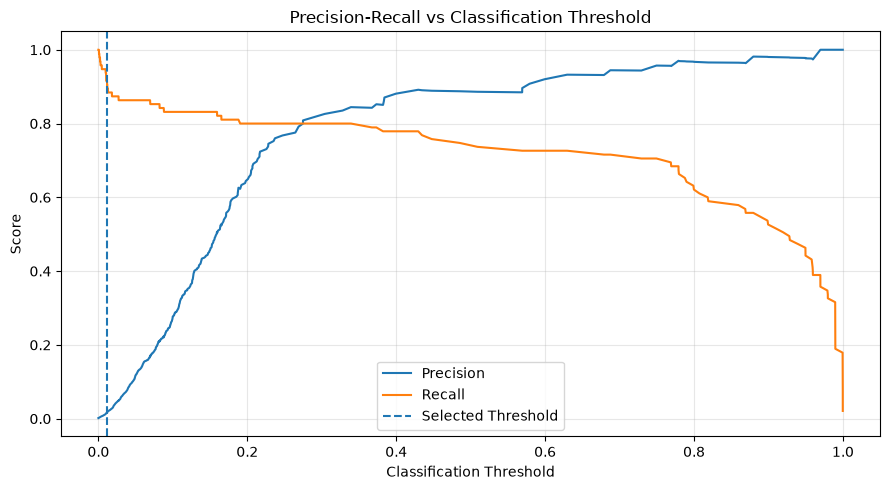

In [38]:
plt.figure(figsize=(9, 5))

plt.plot(
    thresholds,
    precision[:-1],
    label="Precision"
)

plt.plot(
    thresholds,
    recall[:-1],
    label="Recall"
)

plt.axvline(
    best_threshold,
    linestyle="--",
    label="Selected Threshold"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Precision-Recall vs Classification Threshold")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../visualizations/threshold_analysis.png",
    dpi=300
)

plt.show()